# **P719_NLP – Customer Review Sentiment Analysis (BERT vs DistilBERT)**

Fine-tunes two multilingual transformer models to classify customer reviews as **Negative / Neutral / Positive**,
compares them, and exports the best one as a ready-to-deploy **Streamlit** app (section 13).

**How to run (local Jupyter):**
1. Put `P719-Dataset.xlsx` next to this notebook (or in a `data/` folder).
2. Run the cells top to bottom. A GPU makes training much faster, but CPU also works.
3. After section 13, the `deployment/` folder contains everything needed to deploy.


## **1. Import Libraries and Install Packages**


In [ ]:
# Run once, then restart the kernel if pip upgraded anything.
# `%pip` installs into the kernel that is running this notebook (works in Jupyter, JupyterLab and Colab).
%pip install -q "transformers>=4.46" "datasets>=2.19" "accelerate>=0.34" openpyxl scikit-learn seaborn matplotlib ipywidgets

# PyTorch is not installed by the line above. If `import torch` fails, install it for your machine
# (see https://pytorch.org/get-started/locally/), for example:
# %pip install torch


In [2]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import json
import shutil
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.metrics import classification_report, confusion_matrix

from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding, set_seed

# Display settings
pd.set_option('display.max_colwidth', 150)
sns.set_style('whitegrid')

# Reproducibility and shared settings
SEED = 42
MAX_LENGTH = 256   # max tokens per review; the Streamlit app reads the same value from deployment_config.json
set_seed(SEED)

# Check whether GPU is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## **2. Load Dataset**


In [3]:
# Look for the dataset next to the notebook (no hard-coded Colab path)
DATA_FILE = 'P719-Dataset.xlsx'
candidates = [Path(DATA_FILE), Path('data') / DATA_FILE, Path('/content') / DATA_FILE]
file_path = next((p for p in candidates if p.exists()), None)

if file_path is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILE}. Place it next to this notebook or inside a 'data' folder."
    )

df = pd.read_excel(file_path)

# Fail early if the expected columns are missing
required_columns = {'title', 'rating', 'body'}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f'Dataset is missing required columns: {sorted(missing_columns)}')

print('Loaded:', file_path, '| shape:', df.shape)


In [4]:
df.head()

                                     title  rating  \
0                         Horrible product       1   
1  Camera quality is not like 48 megapixel       3   
2                                  Overall       4   
3                         A big no from me       1   
4            Put your money somewhere else       1   

                                                                                                                                                    body  
0                                                                                            Very disappointed with the overall performance from Samsung  
1                                                                                                                                  Camera quality is low  
2  Got the mobile on the launch date,Battery must be appreciatedCamera is just averageMobile performance is above average90hz refresh rate? If u r bu...  
3  1. It doesn't work with 5.0GHz WiFi frequency. 2.4GH

In [5]:
df.shape

(1440, 3)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   1440 non-null   object
 1   rating  1440 non-null   int64 
 2   body    1440 non-null   object
dtypes: int64(1), object(2)
memory usage: 33.9+ KB


In [7]:
df.describe()

            rating
count  1440.000000
mean      3.173611
std       1.584453
min       1.000000
25%       1.000000
50%       4.000000
75%       5.000000
max       5.000000

In [8]:
df.isnull().sum()

,0
title,0
rating,0
body,0


In [9]:
df.columns

Index(['title', 'rating', 'body'], dtype='object')

## **3. Exploratory Data Analysis (EDA)**


In [10]:
# Count of each star rating
df['rating'].value_counts().sort_index()

,count
rating,
1,386
2,126
3,199
4,310
5,419


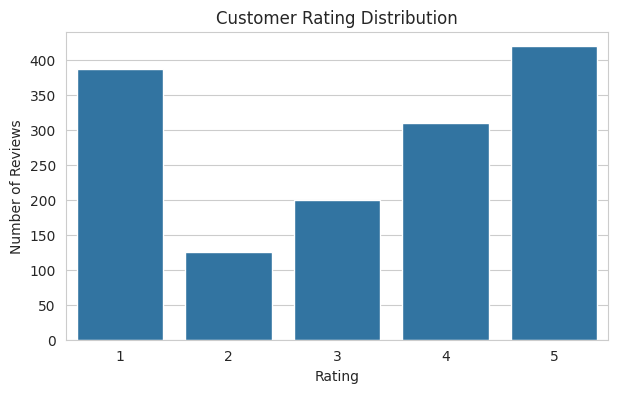

In [11]:
plt.figure(figsize=(7,4))
sns.countplot(x='rating', data=df, order=sorted(df['rating'].dropna().unique()))
plt.title('Customer Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
plt.show()

In [12]:
# Check the length of customer reviews
review_length = df['body'].fillna('').astype(str).str.split().str.len()
review_length.describe()

,body
count,1440.000000
mean,52.892361
std,39.346259
min,1.000000
25%,29.000000
50%,43.000000
75%,63.250000
max,385.000000


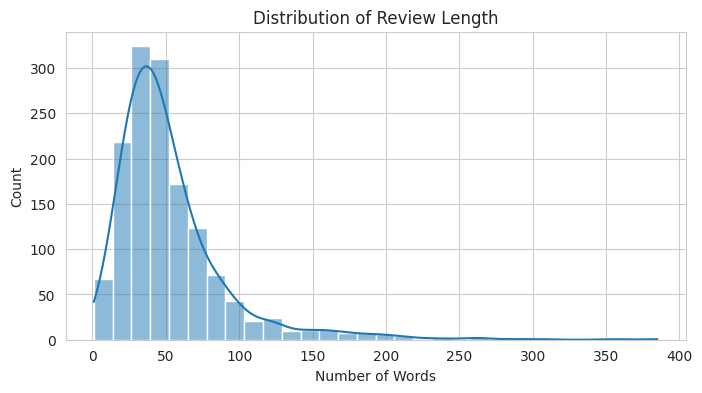

In [13]:
plt.figure(figsize=(8,4))
sns.histplot(review_length, bins=30, kde=True)
plt.title('Distribution of Review Length')
plt.xlabel('Number of Words')
plt.ylabel('Count')
plt.show()

## **4. Data Cleaning and Preparation**

In [14]:
# Check missing values
print(df.isnull().sum())

# Remove rows where rating or review text is missing
df = df.dropna(subset=['rating', 'body']).copy()

# Keep only valid star ratings from 1 to 5
df = df[df['rating'].between(1, 5)].copy()

# Remove duplicate reviews
df = df.drop_duplicates(subset=['title', 'body', 'rating']).copy()

# Clean extra spaces in title and body
df['title'] = df['title'].fillna('').astype(str).str.strip()
df['body'] = df['body'].astype(str).str.strip()

# Combine title and body
# Title may also contain useful sentiment information
df['text'] = (df['title'] + '. ' + df['body']).str.strip()

df = df[df['text'].str.len() > 0].copy()
df.reset_index(drop=True, inplace=True)

print('Shape after cleaning:', df.shape)

title     0
rating    0
body      0
dtype: int64
Shape after cleaning: (1440, 4)


In [15]:
df[['title', 'rating', 'body', 'text']].head()

                                     title  rating  \
0                         Horrible product       1   
1  Camera quality is not like 48 megapixel       3   
2                                  Overall       4   
3                         A big no from me       1   
4            Put your money somewhere else       1   

                                                                                                                                                    body  \
0                                                                                            Very disappointed with the overall performance from Samsung   
1                                                                                                                                  Camera quality is low   
2  Got the mobile on the launch date,Battery must be appreciatedCamera is just averageMobile performance is above average90hz refresh rate? If u r bu...   
3  1. It doesn't work with 5.0GHz WiFi frequency. 2

In [16]:
df.isnull().sum()

,0
title,0
rating,0
body,0
text,0


In [17]:
# Convert star ratings into sentiment labels

def rating_to_sentiment(rating):
    if rating <= 2:
        return 'Negative'
    elif rating == 3:
        return 'Neutral'
    else:
        return 'Positive'

df['sentiment'] = df['rating'].apply(rating_to_sentiment)

# Convert sentiment text into numeric labels
label2id = {'Negative': 0, 'Neutral': 1, 'Positive': 2}
id2label = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
df['label'] = df['sentiment'].map(label2id)

df[['rating', 'sentiment', 'label', 'text']].head()

   rating sentiment  label  \
0       1  Negative      0   
1       3   Neutral      1   
2       4  Positive      2   
3       1  Negative      0   
4       1  Negative      0   

                                                                                                                                                    text  
0                                                                          Horrible product. Very disappointed with the overall performance from Samsung  
1                                                                                         Camera quality is not like 48 megapixel. Camera quality is low  
2  Overall. Got the mobile on the launch date,Battery must be appreciatedCamera is just averageMobile performance is above average90hz refresh rate? ...  
3  A big no from me. 1. It doesn't work with 5.0GHz WiFi frequency. 2.4GHz is very old school.2. Camera quality is pathetic (both front and back). Fo...  
4  Put your money somewhere else. Not worth 

In [18]:
df['sentiment'].value_counts()

,count
sentiment,
Positive,729
Negative,512
Neutral,199


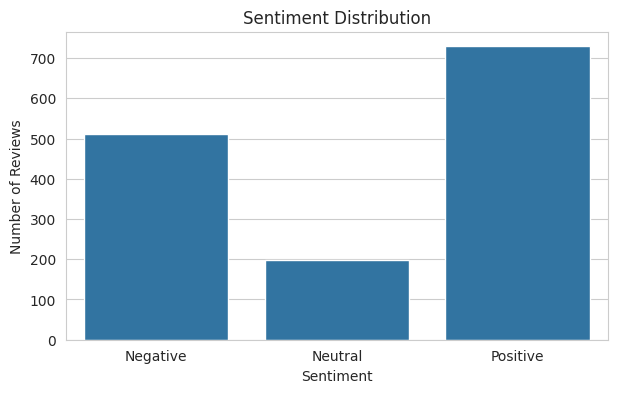

In [19]:
plt.figure(figsize=(7,4))
sns.countplot(x='sentiment', data=df, order=['Negative', 'Neutral', 'Positive'])
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

In [20]:
# Sentiment distribution in percentage
df['sentiment'].value_counts(normalize=True).mul(100).round(2)

,proportion
sentiment,
Positive,50.62
Negative,35.56
Neutral,13.82


## **5. Train, Validation and Test Split**

We will split the dataset into 70% training, 15% validation and 15% testing data.

In [21]:
# First split: 70% training and 30% temporary data
train_df, temp_df = train_test_split(
    df[['text', 'label', 'sentiment']],
    test_size=0.30,
    random_state=SEED,
    stratify=df['label']
)

# Second split: 15% validation and 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df['label']
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print('Training data:', train_df.shape)
print('Validation data:', val_df.shape)
print('Testing data:', test_df.shape)

Training data: (1008, 3)
Validation data: (216, 3)
Testing data: (216, 3)


In [22]:
# Check sentiment distribution in each split
print('Training data')
print(train_df['sentiment'].value_counts(normalize=True).round(3))
print('\nValidation data')
print(val_df['sentiment'].value_counts(normalize=True).round(3))
print('\nTesting data')
print(test_df['sentiment'].value_counts(normalize=True).round(3))

Training data
sentiment
Positive    0.506
Negative    0.356
Neutral     0.138
Name: proportion, dtype: float64

Validation data
sentiment
Positive    0.509
Negative    0.352
Neutral     0.139
Name: proportion, dtype: float64

Testing data
sentiment
Positive    0.505
Negative    0.356
Neutral     0.139
Name: proportion, dtype: float64


## **6. Define Evaluation Metrics**

In [23]:
def compute_metrics(eval_pred):
    logits = eval_pred.predictions
    labels = eval_pred.label_ids

    # Some models may return predictions inside a tuple
    if isinstance(logits, tuple):
        logits = logits[0]

    predictions = np.argmax(logits, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average='macro',
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        'accuracy': accuracy,
        'precision_macro': precision,
        'recall_macro': recall,
        'f1_macro': f1
    }

## **7. BERT Model Building**

In [24]:
bert_model_name = 'google-bert/bert-base-multilingual-cased'

# Load BERT tokenizer
bert_tokenizer = AutoTokenizer.from_pretrained(bert_model_name)

# Tokenize the review text
def bert_tokenize_function(examples):
    return bert_tokenizer(
        examples['text'],
        truncation=True,
        max_length=MAX_LENGTH
    )

In [25]:
# See how BERT splits a customer review into tokens
sample_text = df['text'].iloc[0]
print('Original review:')
print(sample_text)

print('BERT tokens:')
print(bert_tokenizer.tokenize(sample_text))

Original review:
Horrible product. Very disappointed with the overall performance from Samsung
BERT tokens:
['Ho', '##rri', '##ble', 'product', '.', 'Very', 'disa', '##ppo', '##inted', 'with', 'the', 'overall', 'performance', 'from', 'Samsung']


In [26]:
# Convert pandas dataframes into Hugging Face datasets
bert_train_dataset = Dataset.from_pandas(train_df[['text', 'label']], preserve_index=False)
bert_val_dataset = Dataset.from_pandas(val_df[['text', 'label']], preserve_index=False)
bert_test_dataset = Dataset.from_pandas(test_df[['text', 'label']], preserve_index=False)

# Trainer expects the target column to be named labels
bert_train_dataset = bert_train_dataset.rename_column('label', 'labels')
bert_val_dataset = bert_val_dataset.rename_column('label', 'labels')
bert_test_dataset = bert_test_dataset.rename_column('label', 'labels')

# Apply BERT tokenization
bert_train_dataset = bert_train_dataset.map(bert_tokenize_function, batched=True)
bert_val_dataset = bert_val_dataset.map(bert_tokenize_function, batched=True)
bert_test_dataset = bert_test_dataset.map(bert_tokenize_function, batched=True)

# Remove raw text after tokenization
bert_train_dataset = bert_train_dataset.remove_columns(['text'])
bert_val_dataset = bert_val_dataset.remove_columns(['text'])
bert_test_dataset = bert_test_dataset.remove_columns(['text'])

In [27]:
# Load pre-trained BERT for 3-class sequence classification
bert_model = AutoModelForSequenceClassification.from_pretrained(
    bert_model_name,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.

In [28]:
# Dynamic padding for each batch
bert_data_collator = DataCollatorWithPadding(tokenizer=bert_tokenizer)

In [29]:
# Set training parameters
bert_training_args = TrainingArguments(
    output_dir='bert_sentiment_results',
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',
    greater_is_better=True,
    save_total_limit=1,
    fp16=torch.cuda.is_available(),
    report_to='none',
    seed=SEED
)

In [30]:
# Build the BERT trainer
bert_trainer = Trainer(
    model=bert_model,
    args=bert_training_args,
    train_dataset=bert_train_dataset,
    eval_dataset=bert_val_dataset,
    data_collator=bert_data_collator,
    processing_class=bert_tokenizer,
    compute_metrics=compute_metrics
)

In [31]:
# Fit the BERT model
bert_train_result = bert_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,1.912991,0.686002,0.763889,0.508688,0.589474,0.546089
2,1.204998,0.598903,0.782407,0.656423,0.624482,0.612204
3,0.866557,0.613278,0.777778,0.641382,0.644391,0.634414


[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

In [32]:
# Evaluate BERT on the separate test dataset
bert_test_output = bert_trainer.predict(bert_test_dataset)
bert_predictions = np.argmax(bert_test_output.predictions, axis=1)
bert_actual = test_df['label'].values

print('BERT Test Metrics:')
print(bert_test_output.metrics)

BERT Test Metrics:
{'test_loss': 0.5709851384162903, 'test_accuracy': 0.8009259259259259, 'test_precision_macro': 0.6959489324085407, 'test_recall_macro': 0.6718442617525185, 'test_f1_macro': 0.6725424737079863, 'test_runtime': 0.7829, 'test_samples_per_second': 275.902, 'test_steps_per_second': 34.488}


In [33]:
# Classification report for BERT
print(classification_report(
    bert_actual,
    bert_predictions,
    labels=[0, 1, 2],
    target_names=['Negative', 'Neutral', 'Positive'],
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.79      0.88      0.83        77
     Neutral       0.44      0.23      0.30        30
    Positive       0.86      0.90      0.88       109

    accuracy                           0.80       216
   macro avg       0.70      0.67      0.67       216
weighted avg       0.78      0.80      0.78       216



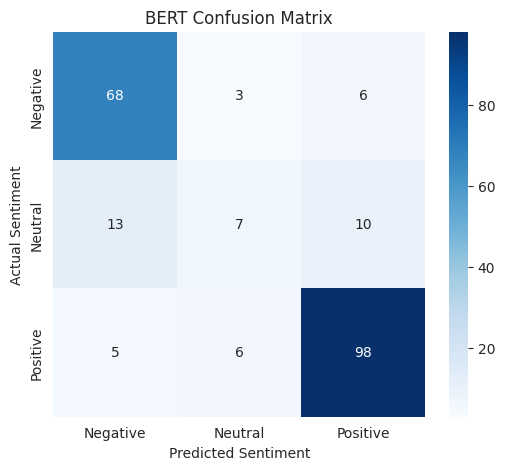

In [34]:
# Confusion matrix for BERT
bert_cm = confusion_matrix(bert_actual, bert_predictions, labels=[0, 1, 2])

plt.figure(figsize=(6,5))
sns.heatmap(
    bert_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)
plt.title('BERT Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()

In [35]:
# Save the fine-tuned BERT model and tokenizer
bert_trainer.save_model('bert_sentiment_model')
bert_tokenizer.save_pretrained('bert_sentiment_model')
print('BERT model saved successfully')

BERT model saved successfully


## **8. DistilBERT Model Building**

In [ ]:
# Free GPU/CPU memory before loading DistilBERT (BERT is already saved and evaluated)
def free_memory(*names):
    # pop() instead of del: re-running this cell never raises NameError
    for name in names:
        globals().pop(name, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

free_memory('bert_trainer', 'bert_model', 'bert_tokenizer')


In [37]:
distilbert_model_name = 'distilbert/distilbert-base-multilingual-cased'

# Load DistilBERT tokenizer
distilbert_tokenizer = AutoTokenizer.from_pretrained(distilbert_model_name)

# Tokenize the review text
def distilbert_tokenize_function(examples):
    return distilbert_tokenizer(
        examples['text'],
        truncation=True,
        max_length=MAX_LENGTH
    )

In [38]:
# Convert pandas dataframes into Hugging Face datasets
distilbert_train_dataset = Dataset.from_pandas(train_df[['text', 'label']], preserve_index=False)
distilbert_val_dataset = Dataset.from_pandas(val_df[['text', 'label']], preserve_index=False)
distilbert_test_dataset = Dataset.from_pandas(test_df[['text', 'label']], preserve_index=False)

# Rename target column for Trainer
distilbert_train_dataset = distilbert_train_dataset.rename_column('label', 'labels')
distilbert_val_dataset = distilbert_val_dataset.rename_column('label', 'labels')
distilbert_test_dataset = distilbert_test_dataset.rename_column('label', 'labels')

# Apply DistilBERT tokenization
distilbert_train_dataset = distilbert_train_dataset.map(distilbert_tokenize_function, batched=True)
distilbert_val_dataset = distilbert_val_dataset.map(distilbert_tokenize_function, batched=True)
distilbert_test_dataset = distilbert_test_dataset.map(distilbert_tokenize_function, batched=True)

# Remove raw text after tokenization
distilbert_train_dataset = distilbert_train_dataset.remove_columns(['text'])
distilbert_val_dataset = distilbert_val_dataset.remove_columns(['text'])
distilbert_test_dataset = distilbert_test_dataset.remove_columns(['text'])

In [39]:
# Load pre-trained DistilBERT for 3-class classification
distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    distilbert_model_name,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [40]:
# Dynamic padding for each batch
distilbert_data_collator = DataCollatorWithPadding(tokenizer=distilbert_tokenizer)

In [41]:
# Set training parameters
distilbert_training_args = TrainingArguments(
    output_dir='distilbert_sentiment_results',
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',
    greater_is_better=True,
    save_total_limit=1,
    fp16=torch.cuda.is_available(),
    report_to='none',
    seed=SEED
)

In [42]:
# Build the DistilBERT trainer
distilbert_trainer = Trainer(
    model=distilbert_model,
    args=distilbert_training_args,
    train_dataset=distilbert_train_dataset,
    eval_dataset=distilbert_val_dataset,
    data_collator=distilbert_data_collator,
    processing_class=distilbert_tokenizer,
    compute_metrics=compute_metrics
)

In [43]:
# Fit the DistilBERT model
distilbert_train_result = distilbert_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,1.823510,0.732726,0.703704,0.467011,0.537879,0.499625
2,1.163521,0.680986,0.731481,0.622596,0.576289,0.557729
3,0.909541,0.676624,0.740741,0.586310,0.590484,0.567178


In [44]:
# Evaluate DistilBERT on the same test dataset
distilbert_test_output = distilbert_trainer.predict(distilbert_test_dataset)
distilbert_predictions = np.argmax(distilbert_test_output.predictions, axis=1)
distilbert_actual = test_df['label'].values

print('DistilBERT Test Metrics:')
print(distilbert_test_output.metrics)

DistilBERT Test Metrics:
{'test_loss': 0.6006255149841309, 'test_accuracy': 0.7824074074074074, 'test_precision_macro': 0.7411636435722073, 'test_recall_macro': 0.6206177105259675, 'test_f1_macro': 0.5956579419851625, 'test_runtime': 0.4516, 'test_samples_per_second': 478.307, 'test_steps_per_second': 59.788}


In [45]:
# Classification report for DistilBERT
print(classification_report(
    distilbert_actual,
    distilbert_predictions,
    labels=[0, 1, 2],
    target_names=['Negative', 'Neutral', 'Positive'],
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.73      0.90      0.80        77
     Neutral       0.67      0.07      0.12        30
    Positive       0.83      0.90      0.86       109

    accuracy                           0.78       216
   macro avg       0.74      0.62      0.60       216
weighted avg       0.77      0.78      0.74       216



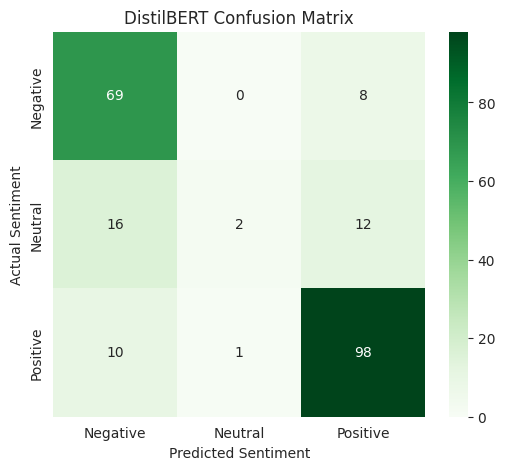

In [46]:
# Confusion matrix for DistilBERT
distilbert_cm = confusion_matrix(distilbert_actual, distilbert_predictions, labels=[0, 1, 2])

plt.figure(figsize=(6,5))
sns.heatmap(
    distilbert_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)
plt.title('DistilBERT Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()

In [47]:
# Save the fine-tuned DistilBERT model and tokenizer
distilbert_trainer.save_model('distilbert_sentiment_model')
distilbert_tokenizer.save_pretrained('distilbert_sentiment_model')
print('DistilBERT model saved successfully')

DistilBERT model saved successfully


In [ ]:
# Free memory used by DistilBERT
free_memory('distilbert_trainer', 'distilbert_model', 'distilbert_tokenizer')


## **9. Model Comparison**

In [49]:
comparison_df = pd.DataFrame({
    'Model': ['BERT', 'DistilBERT'],
    'Accuracy': [
        bert_test_output.metrics['test_accuracy'],
        distilbert_test_output.metrics['test_accuracy']
    ],
    'Precision (Macro)': [
        bert_test_output.metrics['test_precision_macro'],
        distilbert_test_output.metrics['test_precision_macro']
    ],
    'Recall (Macro)': [
        bert_test_output.metrics['test_recall_macro'],
        distilbert_test_output.metrics['test_recall_macro']
    ],
    'F1-score (Macro)': [
        bert_test_output.metrics['test_f1_macro'],
        distilbert_test_output.metrics['test_f1_macro']
    ]
})

comparison_df

        Model  Accuracy  Precision (Macro)  Recall (Macro)  F1-score (Macro)
0        BERT  0.800926           0.695949        0.671844          0.672542
1  DistilBERT  0.782407           0.741164        0.620618          0.595658

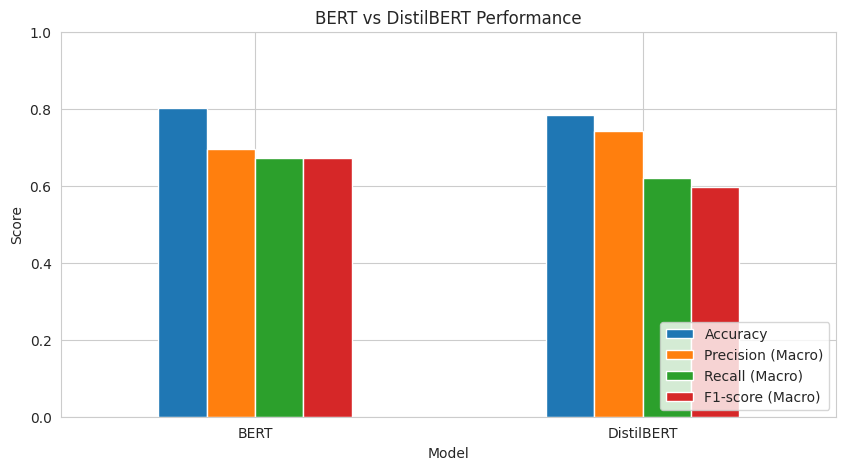

In [50]:
comparison_df.set_index('Model')[['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-score (Macro)']].plot(
    kind='bar', figsize=(10,5), ylim=(0,1)
)
plt.title('BERT vs DistilBERT Performance')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [51]:
best_model_name = comparison_df.loc[
    comparison_df['F1-score (Macro)'].idxmax(), 'Model'
]
print('Best model based on Macro F1-score:', best_model_name)

Best model based on Macro F1-score: BERT


## **10. Save Test Predictions**

In [52]:
prediction_results = test_df[['text', 'sentiment']].copy()
prediction_results['BERT_Prediction'] = [id2label[int(i)] for i in bert_predictions]
prediction_results['DistilBERT_Prediction'] = [id2label[int(i)] for i in distilbert_predictions]

prediction_results.head(10)

                                                                                                                                                    text  \
0                         Average. No doubt mobile just awesome. But camera quality below average. I have Samsung galaxy j7 nxt. Better picture from M12   
1  Very Nice phone. I purchased it for the 6GB+128GB combination. Though knowing that the processor capacity could be less. But it is indeed a surpri...   
2                                                                                                         Heating. Major heating problem during charging   
3  Nothing. As far as my opinion is concerned, the over all features are Ok. The drawback features are:1. M12 is out of Super Amolrd Screen.2. Back F...   
4  Budget mobile !. Model : Samsung m12 6gb RAM 128 ROM (Black)Bought @ 10,350rsBattery life - 8/10Fingerprint, face recognition- 9/10Camera Quality-...   
5  Amazon service. The phone is too heavy to handle camera is to

In [53]:
prediction_results.to_csv('sentiment_model_test_predictions.csv', index=False)
print('Test predictions saved successfully')

Test predictions saved successfully


## **11. Predict Sentiment for a New Review**

The following function loads a saved fine-tuned model and predicts the sentiment of a new customer review.

In [ ]:
_MODEL_CACHE = {}   # loaded once per model folder instead of on every call


def _load_for_inference(model_folder):
    key = str(Path(model_folder).resolve())
    if key not in _MODEL_CACHE:
        tokenizer = AutoTokenizer.from_pretrained(model_folder)
        model = AutoModelForSequenceClassification.from_pretrained(model_folder)
        model.to(device).eval()
        _MODEL_CACHE[key] = (tokenizer, model)
    return _MODEL_CACHE[key]


def predict_review(review_text, model_folder):
    """Return (sentiment, confidence) for one review using a saved model folder."""
    if not isinstance(review_text, str) or not review_text.strip():
        raise ValueError('review_text must be a non-empty string')

    tokenizer, model = _load_for_inference(model_folder)

    inputs = tokenizer(
        review_text,
        return_tensors='pt',
        truncation=True,
        max_length=MAX_LENGTH
    )
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.inference_mode():
        probabilities = torch.softmax(model(**inputs).logits, dim=-1)[0]

    predicted_id = int(probabilities.argmax().item())
    return id2label[predicted_id], float(probabilities[predicted_id].item())


In [55]:
# Enter a new customer review
new_review = 'The camera quality is excellent and the battery backup is very good.'

In [56]:
# BERT prediction
bert_sentiment, bert_confidence = predict_review(
    new_review,
    'bert_sentiment_model'
)
print('BERT Sentiment:', bert_sentiment)
print('BERT Confidence:', round(bert_confidence, 4))

BERT Sentiment: Positive
BERT Confidence: 0.9423


In [57]:
# DistilBERT prediction
distilbert_sentiment, distilbert_confidence = predict_review(
    new_review,
    'distilbert_sentiment_model'
)
print('DistilBERT Sentiment:', distilbert_sentiment)
print('DistilBERT Confidence:', round(distilbert_confidence, 4))

DistilBERT Sentiment: Positive
DistilBERT Confidence: 0.8641


## **12. Final Findings and Limitations**

### Findings
1. Both BERT and DistilBERT were fine-tuned for three-class customer-review sentiment classification.
2. Both models used the same train, validation and test split.
3. Macro F1-score was used because it gives equal weight to each sentiment class.
4. **BERT is the best model**: test accuracy 80.1% and macro F1 0.673, against 78.2% and 0.596 for DistilBERT.
5. Both models work well on *Negative* (F1 0.83 BERT / 0.80 DistilBERT) and *Positive* (0.88 / 0.86).
6. The *Neutral* class is weak: recall is only 0.23 for BERT and 0.07 for DistilBERT, so most neutral reviews are pushed into the Negative or Positive class.

### Limitations
- **Small dataset**: 1,440 reviews in total; the test set has 216 reviews and only 30 are Neutral, so the metrics (especially Neutral) are uncertain.
- **Class imbalance**: Neutral is about 14% of the data and no class weighting or resampling was used.
- **Labels come from star ratings** (1-2 = Negative, 3 = Neutral, 4-5 = Positive). A 3-star review can read as positive or negative, so the labels are noisy.
- **Single product domain**: the reviews are about one mobile phone (Samsung M12), so accuracy may drop for other products.
- **One train/validation/test split** and one random seed; no cross-validation.
- Reviews are truncated to 256 tokens.

### Ideas to improve
Class-weighted loss or oversampling of Neutral, more labelled Neutral data, cross-validation, and trying other models such as XLM-RoBERTa.


## **13. Deployment Using Streamlit**

This section turns the trained notebook into a deployable package (`deployment/` folder):

1. **13.1** reloads the saved models from disk and checks they reproduce the test results (catches broken saves).
2. **13.2** copies the best model and writes `deployment_config.json`.
3. **13.3** writes `app.py`, `requirements.txt`, `README.md` and `.gitignore`.
4. **13.4** optional: upload the model to the Hugging Face Hub and zip the package.

### 13.1 Verify the saved models

In [ ]:
def evaluate_saved_model(folder, data, batch_size=32):
    """Reload a saved model from disk and predict the label ids for data['text']."""
    tokenizer = AutoTokenizer.from_pretrained(folder)
    model = AutoModelForSequenceClassification.from_pretrained(folder)
    model.to(device).eval()

    # The label mapping stored in the model must match the notebook's mapping
    saved_id2label = {int(k): v for k, v in model.config.id2label.items()}
    assert saved_id2label == id2label, f'Label mapping mismatch in {folder}: {saved_id2label}'

    texts = data['text'].tolist()
    predictions = []
    for start in range(0, len(texts), batch_size):
        enc = tokenizer(texts[start:start + batch_size], return_tensors='pt',
                        truncation=True, max_length=MAX_LENGTH, padding=True)
        enc = {key: value.to(device) for key, value in enc.items()}
        with torch.inference_mode():
            predictions.extend(model(**enc).logits.argmax(dim=-1).cpu().tolist())

    free_memory('model', 'tokenizer')
    return np.array(predictions)


model_folder_map = {
    'BERT': 'bert_sentiment_model',
    'DistilBERT': 'distilbert_sentiment_model'
}
reference_metrics = {
    'BERT': bert_test_output.metrics,
    'DistilBERT': distilbert_test_output.metrics
}

for name, folder in model_folder_map.items():
    if not Path(folder).exists():
        raise FileNotFoundError(f"Saved model folder '{folder}' not found. Run the training and save cells first.")

    reloaded_predictions = evaluate_saved_model(folder, test_df)
    reloaded_accuracy = accuracy_score(test_df['label'].values, reloaded_predictions)
    training_accuracy = reference_metrics[name]['test_accuracy']
    difference = abs(reloaded_accuracy - training_accuracy)

    print(f'{name}: accuracy from saved model = {reloaded_accuracy:.4f} | '
          f'accuracy during training run = {training_accuracy:.4f} | difference = {difference:.4f}')

    # A tiny difference is normal (fp16 vs fp32). A large one means the saved weights are wrong.
    if difference > 0.02:
        raise RuntimeError(f'{name}: the saved model does not reproduce the test accuracy. Re-run training and saving.')

print('\nSaved models verified.')

### 13.2 Export the best model and write the deployment config

In [ ]:
# Best model = highest macro F1 (section 9)
best_model_folder = Path(model_folder_map[best_model_name])
best_base_model = {'BERT': bert_model_name, 'DistilBERT': distilbert_model_name}[best_model_name]
best_predictions = bert_predictions if best_model_name == 'BERT' else distilbert_predictions

best_report = classification_report(
    test_df['label'].values,
    best_predictions,
    labels=[0, 1, 2],
    target_names=['Negative', 'Neutral', 'Positive'],
    output_dict=True,
    zero_division=0
)

DEPLOY_DIR = Path('deployment')
MODEL_DIR = DEPLOY_DIR / 'model'
DEPLOY_DIR.mkdir(exist_ok=True)

# Copy only what inference needs (no checkpoints / training arguments)
if MODEL_DIR.exists():
    shutil.rmtree(MODEL_DIR)
shutil.copytree(best_model_folder, MODEL_DIR,
                ignore=shutil.ignore_patterns('checkpoint-*', 'training_args.bin'))

deployment_config = {
    'best_model': best_model_name,
    'base_model': best_base_model,
    'model_path': 'model',
    'max_length': MAX_LENGTH,
    'labels': [id2label[i] for i in sorted(id2label)],
    'metrics': comparison_df.set_index('Model').round(4).to_dict(orient='index'),
    'neutral_recall': round(best_report['Neutral']['recall'], 4),
    'test_size': int(len(test_df))
}
(DEPLOY_DIR / 'deployment_config.json').write_text(json.dumps(deployment_config, indent=2), encoding='utf-8')

model_size_mb = sum(f.stat().st_size for f in MODEL_DIR.rglob('*') if f.is_file()) / 1e6
print('Best model:', best_model_name)
print(f'Exported to: {MODEL_DIR.resolve()}  ({model_size_mb:.0f} MB)')
print('Files:', sorted(f.name for f in MODEL_DIR.iterdir()))
print(json.dumps(deployment_config, indent=2))

### 13.3 Write the Streamlit app and project files

The next four cells write `app.py`, `requirements.txt`, `README.md` and `.gitignore` into `deployment/`.

In [ ]:
%%writefile deployment/app.py
"""
P719 - Customer Review Sentiment Analyzer (Streamlit app)

Run locally:   streamlit run app.py

Where the model is loaded from (first match wins):
  1. Streamlit secret  MODEL_SOURCE
  2. Environment var   MODEL_SOURCE
  3. "model_path" in deployment_config.json (default: ./model next to this file)
MODEL_SOURCE can be a local folder or a Hugging Face Hub repo id ("username/repo").
For a private Hub repo also set HF_TOKEN.
"""

import json
import os
import re
from pathlib import Path

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import pandas as pd
import streamlit as st
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# --------------------------------------------------------------------------- #
# Config
# --------------------------------------------------------------------------- #
APP_DIR = Path(__file__).resolve().parent
CONFIG_FILE = APP_DIR / "deployment_config.json"

DEFAULT_CONFIG = {
    "best_model": "BERT",
    "model_path": "model",
    "max_length": 256,
    "labels": ["Negative", "Neutral", "Positive"],
    "metrics": {},
    "neutral_recall": None,
}


def load_config() -> dict:
    cfg = dict(DEFAULT_CONFIG)
    if CONFIG_FILE.exists():
        try:
            cfg.update(json.loads(CONFIG_FILE.read_text(encoding="utf-8")))
        except (OSError, ValueError):
            pass  # fall back to defaults
    return cfg


CFG = load_config()
LABELS = CFG["labels"]
MAX_LENGTH = int(CFG["max_length"])
MAX_CHARS = 5000        # hard cap on characters per review (model reads max_length tokens)
MAX_BATCH_ROWS = 500    # CPU-friendly limit for CSV scoring
EMOJI = {"Negative": "😠", "Neutral": "😐", "Positive": "😊"}

EXAMPLES = {
    "Positive": "Great phone. The camera quality is excellent and the battery backup is very good.",
    "Negative": "Heating. Major heating problem during charging, very disappointed.",
    "Mixed / Neutral": "Average. Display is fine but the camera is just okay for the price.",
}

st.set_page_config(page_title="Review Sentiment Analyzer", page_icon="💬", layout="centered")


def get_model_source() -> str:
    try:
        if "MODEL_SOURCE" in st.secrets:
            return str(st.secrets["MODEL_SOURCE"])
    except Exception:  # no secrets file available
        pass
    env_value = os.getenv("MODEL_SOURCE")
    if env_value:
        return env_value
    return str(APP_DIR / CFG["model_path"])


def is_hub_repo_id(value: str) -> bool:
    return re.fullmatch(r"[\w.-]+/[\w.-]+", value) is not None


# --------------------------------------------------------------------------- #
# Model
# --------------------------------------------------------------------------- #
@st.cache_resource(show_spinner="Loading model (first start can take a minute)...")
def load_model(source: str):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tokenizer = AutoTokenizer.from_pretrained(source)
    model = AutoModelForSequenceClassification.from_pretrained(source)
    model.to(device).eval()
    return tokenizer, model, device


def predict(texts, tokenizer, model, device, batch_size=16):
    """Score a list of texts. Returns a list of dicts: label, confidence, probs."""
    id2label = {int(k): v for k, v in model.config.id2label.items()}
    rows = []
    for start in range(0, len(texts), batch_size):
        batch = [t[:MAX_CHARS] for t in texts[start : start + batch_size]]
        enc = tokenizer(
            batch, return_tensors="pt", truncation=True, max_length=MAX_LENGTH, padding=True
        )
        enc = {k: v.to(device) for k, v in enc.items()}
        with torch.inference_mode():
            probs = torch.softmax(model(**enc).logits, dim=-1).cpu()
        for p in probs:
            idx = int(p.argmax())
            rows.append(
                {
                    "label": id2label[idx],
                    "confidence": float(p[idx]),
                    "probs": {id2label[j]: float(p[j]) for j in range(p.shape[0])},
                }
            )
    return rows


# --------------------------------------------------------------------------- #
# Sidebar
# --------------------------------------------------------------------------- #
best = CFG["best_model"]
best_metrics = CFG["metrics"].get(best, {})

with st.sidebar:
    st.header("About the model")
    st.write(f"**Model:** fine-tuned {best} (multilingual, cased)")
    if "Accuracy" in best_metrics:
        st.metric("Test accuracy", f"{best_metrics['Accuracy']:.1%}")
    if "F1-score (Macro)" in best_metrics:
        st.metric("Test macro F1", f"{best_metrics['F1-score (Macro)']:.3f}")
    st.markdown("---")
    st.markdown(
        "**Known limitations**\n"
        "- *Neutral* (3-star) reviews are the hardest class"
        + (f" (recall ≈ {CFG['neutral_recall']:.0%} on the test set)" if CFG["neutral_recall"] is not None else "")
        + ".\n"
        "- Trained on ~1,400 mobile-phone reviews; other product types may score worse.\n"
        f"- Only the first {MAX_LENGTH} tokens of a review are read."
    )

# --------------------------------------------------------------------------- #
# Load model (with clear error messages)
# --------------------------------------------------------------------------- #
source = get_model_source()
if not Path(source).exists() and not is_hub_repo_id(source):
    st.error(
        f"Model not found at `{source}`.\n\n"
        "Put the exported `model/` folder next to `app.py`, or set `MODEL_SOURCE` "
        "to a Hugging Face repo id such as `username/bert-sentiment`."
    )
    st.stop()

try:
    tokenizer, model, device = load_model(source)
except Exception as exc:  # noqa: BLE001
    st.error(f"Could not load the model from `{source}`.\n\n{exc}")
    st.stop()

# --------------------------------------------------------------------------- #
# Main UI
# --------------------------------------------------------------------------- #
st.title("💬 Customer Review Sentiment Analyzer")
st.caption("Classifies a review as Negative, Neutral or Positive.")

tab_single, tab_batch = st.tabs(["Single review", "Batch (CSV)"])

with tab_single:
    example = st.selectbox("Load an example (optional)", ["—"] + list(EXAMPLES))
    review = st.text_area(
        "Customer review",
        value=EXAMPLES.get(example, ""),
        height=160,
        key=f"review_{example}",  # refreshes the box when the example changes
        placeholder="Type or paste a review here...",
    )

    if st.button("Analyze sentiment", type="primary"):
        if not review.strip():
            st.warning("Please enter some review text.")
        else:
            result = predict([review.strip()], tokenizer, model, device)[0]
            label, conf = result["label"], result["confidence"]

            st.subheader(f"{EMOJI.get(label, '')} {label}")
            st.progress(min(max(conf, 0.0), 1.0), text=f"Confidence: {conf:.1%}")
            st.bar_chart(pd.DataFrame({"Probability": [result["probs"].get(l, 0.0) for l in LABELS]}, index=LABELS))

            if len(review) > MAX_CHARS:
                st.info(f"Review was cut to the first {MAX_CHARS} characters.")
            if conf < 0.60:
                st.info("Low confidence: the review may be mixed or ambiguous.")
            if label == "Neutral":
                st.info("Neutral is the model's weakest class, so double-check this result.")

with tab_batch:
    upload = st.file_uploader("Upload a CSV file that has a review-text column", type=["csv"])
    if upload is not None:
        try:
            data = pd.read_csv(upload, encoding_errors="replace")
        except Exception as exc:  # noqa: BLE001
            data = None
            st.error(f"Could not read the CSV file: {exc}")

        if data is not None and data.empty:
            st.warning("The uploaded CSV has no rows.")
        elif data is not None:
            text_col = st.selectbox("Column that contains the review text", list(data.columns))
            if len(data) > MAX_BATCH_ROWS:
                st.warning(f"Only the first {MAX_BATCH_ROWS} rows will be scored.")
                data = data.head(MAX_BATCH_ROWS).copy()

            if st.button("Run batch prediction"):
                texts = data[text_col].fillna("").astype(str).tolist()
                with st.spinner("Scoring reviews..."):
                    scored = predict(texts, tokenizer, model, device)
                data["predicted_sentiment"] = [r["label"] for r in scored]
                data["confidence"] = [round(r["confidence"], 4) for r in scored]

                st.dataframe(data)
                st.bar_chart(data["predicted_sentiment"].value_counts().reindex(LABELS, fill_value=0))
                st.download_button(
                    "Download results (CSV)",
                    data.to_csv(index=False).encode("utf-8"),
                    file_name="sentiment_predictions.csv",
                    mime="text/csv",
                )

st.markdown("---")
st.caption("P719 · NLP · Fine-tuned on mobile-phone customer reviews (Samsung M12).")

In [ ]:
%%writefile deployment/requirements.txt
--extra-index-url https://download.pytorch.org/whl/cpu
streamlit>=1.38
torch>=2.2
transformers>=4.46
pandas>=2.0
safetensors>=0.4
huggingface_hub>=0.24

In [ ]:
%%writefile deployment/README.md
# P719 – Customer Review Sentiment Analyzer

Fine-tuned multilingual BERT classifier (Negative / Neutral / Positive) served with Streamlit.

## Folder layout
```
deployment/
├── app.py                    # Streamlit app
├── deployment_config.json    # best model name, labels, test metrics (written by the notebook)
├── requirements.txt
└── model/                    # exported model + tokenizer (created by the notebook, section 13)
```

## 1. Run locally
```bash
python -m venv .venv && source .venv/bin/activate      # Windows: .venv\Scripts\activate
pip install -r requirements.txt
streamlit run app.py
```

## 2. Host the model on the Hugging Face Hub (recommended)
GitHub rejects files over 100 MB and the model is ~700 MB, so upload it to the Hub:
```python
from huggingface_hub import HfApi
api = HfApi()                                   # run `huggingface-cli login` first
api.create_repo("YOUR_USERNAME/bert-sentiment", exist_ok=True)
api.upload_folder(folder_path="model", repo_id="YOUR_USERNAME/bert-sentiment")
```

## 3. Deploy
**Streamlit Community Cloud** – push `app.py`, `requirements.txt`, `deployment_config.json` to GitHub, create the app,
then add this in *Settings → Secrets*:
```toml
MODEL_SOURCE = "YOUR_USERNAME/bert-sentiment"
```
Community Cloud has ~1 GB RAM; if the app runs out of memory while loading BERT, use **Hugging Face Spaces**
(Streamlit SDK, more RAM) with the same files, or deploy DistilBERT instead.

**Hugging Face Spaces** – create a Streamlit Space, upload the same files, and put this at the top of `README.md`:
```yaml
---
title: Review Sentiment Analyzer
sdk: streamlit
app_file: app.py
---
```
Set `MODEL_SOURCE` as a Space variable/secret.

## Notes
- The first request after a cold start is slow (model loading); later requests are fast.
- Neutral (3-star) reviews are the weakest class; see section 12 of the notebook.

In [ ]:
%%writefile deployment/.gitignore
__pycache__/
*.pyc
.streamlit/secrets.toml
# Model weights are too big for GitHub (100 MB limit): host them on the Hugging Face Hub
# and set MODEL_SOURCE. Delete the next line only if you deploy with Git LFS / HF Spaces.
model/
*.zip

### 13.4 Test locally, then deploy

Open a terminal in the `deployment/` folder and run:

```bash
pip install -r requirements.txt
streamlit run app.py
```

To deploy on **Streamlit Community Cloud** or **Hugging Face Spaces**, first upload the model to the Hugging Face Hub
(optional cell below), then follow `deployment/README.md`.

In [ ]:
# OPTIONAL: upload the exported model to the Hugging Face Hub (needed because the model is too big for GitHub).
# 1) Create a free account and a *write* token at https://huggingface.co/settings/tokens
# 2) Set HF_REPO_ID below and change UPLOAD_TO_HUB to True.
UPLOAD_TO_HUB = False
HF_REPO_ID = 'YOUR_USERNAME/bert-sentiment'

if UPLOAD_TO_HUB:
    from huggingface_hub import HfApi, login
    login()  # paste the token when asked (it is not stored in the notebook)
    api = HfApi()
    api.create_repo(HF_REPO_ID, exist_ok=True)
    api.upload_folder(folder_path=str(MODEL_DIR), repo_id=HF_REPO_ID)
    print('Uploaded. Set MODEL_SOURCE =', HF_REPO_ID, 'in your Streamlit secrets.')
else:
    print('Skipped upload (UPLOAD_TO_HUB is False).')

In [ ]:
# OPTIONAL: zip the whole deployment folder so it is easy to download or share
archive_path = shutil.make_archive('deployment_package', 'zip', root_dir='.', base_dir='deployment')
print('Created:', archive_path)
for f in sorted(DEPLOY_DIR.iterdir()):
    print('-', f.name)